# Credit Risk Assessment — Final Modeling Pipeline

## 1. Modeling Objective

The objective is to develop a credit-risk classification model that predicts whether a borrower will experience serious delinquency within two years.

### Target Variable

- `SeriousDlqin2yrs`
- `0` → No serious delinquency
- `1` → Serious delinquency

The dataset is highly imbalanced, with the positive class representing a small proportion of observations. Therefore, accuracy alone is not an appropriate primary evaluation metric.

### Modeling Priorities

The modeling process will prioritize:

1. **PR-AUC** — primary model-selection metric because of class imbalance.
2. **ROC-AUC** — overall ranking/discrimination ability.
3. **KS statistic** — separation between positive and negative classes.
4. **Brier score** — probability quality/calibration.
5. **Recall** — ability to identify high-risk borrowers.
6. **Precision** — proportion of flagged borrowers who are actually high-risk.
7. **F1-score** — balance between precision and recall.
8. **Business metric at the selected decision threshold.**

Accuracy will be reported as a supplementary metric but will not be used as the primary model-selection criterion.

---

## Modeling Methodology

The modeling workflow follows a leakage-controlled sequence:

1. Leakage and data-integrity checks
2. Train/test split
3. Test-set lock
4. Preprocessing pipeline
5. Baseline model comparison
6. Class-weighting experiment
7. Feature ablation
8. Monotonic-constraint experiment
9. Hyperparameter tuning
10. Freeze the complete predictive pipeline
11. Generate out-of-fold (OOF) predictions
12. Probability calibration
13. Decision-threshold selection
14. One-time final test evaluation
15. Explainability, fairness, and robustness analysis
16. Artifact creation
17. Deployment monitoring design

### Important Leakage Rule

The test set will remain completely isolated until final evaluation.

The test set will not be used for:

- feature selection
- feature ablation
- model selection
- hyperparameter tuning
- calibration
- threshold selection
- SHAP-driven model modification
- fairness-driven model modification
- robustness-driven model modification

Any issue discovered after final evaluation will be documented as a potential future model iteration rather than used to modify the evaluated model.

In [1]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = ["IncomeCategory"]

numeric_cols = X_dev.columns.difference(
    categorical_cols
).tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        ),
        (
            "numeric",
            "passthrough",
            numeric_cols
        )
    ],
    remainder="drop"
)

print("Numeric features:", len(numeric_cols))
print("Categorical features:", categorical_cols)

NameError: name 'X_dev' is not defined

# 2. Train/Test Split and Test-Set Lock

The cleaned and feature-engineered dataset from the preprocessing/EDA phase is used as the input to modeling.

All data-quality, preprocessing, feature-engineering, and leakage checks were completed during the previous phase.

The dataset is divided into:

- **80% development set** — used for all model development, cross-validation, feature experiments, tuning, calibration, and threshold selection.
- **20% test set** — completely locked until final evaluation.

A stratified split is used because the target variable is highly imbalanced.

The test set will not be used for:

- model selection
- feature selection or ablation
- hyperparameter tuning
- calibration
- threshold selection
- explainability-driven model changes
- fairness-driven model changes
- robustness-driven model changes

The test set will be evaluated exactly once after the complete predictive pipeline has been frozen.

In [1]:
import pandas as pd
df_model= pd.read_csv("../Data/Processed/credit_feature_engineered.csv")
df_model.shape

(149999, 21)

In [2]:
from sklearn.model_selection import train_test_split

TARGET = "SeriousDlqin2yrs"

X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Development set:", X_dev.shape)
print("Test set:", X_test.shape)

print("\nDevelopment target distribution:")
display(y_dev.value_counts(normalize=True))

print("\nTest target distribution:")
display(y_test.value_counts(normalize=True))

print("Overall positive rate:      ", y.mean())
print("Development positive rate:  ", y_dev.mean())
print("Test positive rate:         ", y_test.mean())

Development set: (119999, 20)
Test set: (30000, 20)

Development target distribution:


SeriousDlqin2yrs
0    0.933158
1    0.066842
Name: proportion, dtype: float64


Test target distribution:


SeriousDlqin2yrs
0    0.933167
1    0.066833
Name: proportion, dtype: float64

Overall positive rate:       0.06684044560297069
Development positive rate:   0.06684222368519738
Test positive rate:          0.06683333333333333


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = ["IncomeCategory"]

numeric_cols = X_dev.columns.difference(
    categorical_cols
).tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        ),
        (
            "numeric",
            "passthrough",
            numeric_cols
        )
    ],
    remainder="drop"
)

print("Numeric features:", len(numeric_cols))
print("Categorical features:", categorical_cols)

Numeric features: 19
Categorical features: ['IncomeCategory']


In [4]:
# Lock test data
X_test_locked = X_test.copy()
y_test_locked = y_test.copy()

# Development data is the only data used from this point
X_dev = X_dev.copy()
y_dev = y_dev.copy()

print("Test set locked.")
print(f"Locked test observations: {len(X_test_locked):,}")
print(f"Development observations: {len(X_dev):,}")

Test set locked.
Locked test observations: 30,000
Development observations: 119,999


In [6]:
# Check non-numeric columns in development features
categorical_cols = X_dev.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumber of categorical columns:", len(categorical_cols))

for col in categorical_cols:
    print(f"\n{col}:")
    print(X_dev[col].value_counts(dropna=False).head(10))
print(X_dev.dtypes.value_counts())

Categorical columns:
['IncomeCategory']

Number of categorical columns: 1

IncomeCategory:
IncomeCategory
Lower-Middle    47746
Low             24228
High            24065
Upper-Middle    23960
Name: count, dtype: int64
float64    11
int64       8
str         1
Name: count, dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_11840\2227970054.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_dev.select_dtypes(


# 3. Cross-Validation Strategy

All model-development experiments use the same fixed repeated stratified folds.

Repeated stratification preserves the minority-class proportion in each validation fold while providing multiple train/validation partitions.

The folds are generated once from the development set and reused throughout:

- baseline model comparison
- class-weighting experiment
- feature ablation
- monotonic constraint experiment
- hyperparameter tuning
- OOF prediction generation

The test set is not involved in cross-validation.

In [7]:
from sklearn.model_selection import RepeatedStratifiedKFold

CV = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=42
)

print("Cross-validation strategy:")
print("  Folds per repeat: 5")
print("  Repeats: 2")
print("  Total validation folds: 10")
print("  Random state: 42")

Cross-validation strategy:
  Folds per repeat: 5
  Repeats: 2
  Total validation folds: 10
  Random state: 42


In [8]:
cv_splits = list(CV.split(X_dev, y_dev))

print(f"Stored CV splits: {len(cv_splits)}")

for i, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    print(
        f"Fold {i}: "
        f"train={len(train_idx):,}, "
        f"validation={len(val_idx):,}"
    )

Stored CV splits: 10
Fold 1: train=95,999, validation=24,000
Fold 2: train=95,999, validation=24,000
Fold 3: train=95,999, validation=24,000
Fold 4: train=95,999, validation=24,000
Fold 5: train=96,000, validation=23,999
Fold 6: train=95,999, validation=24,000
Fold 7: train=95,999, validation=24,000
Fold 8: train=95,999, validation=24,000
Fold 9: train=95,999, validation=24,000
Fold 10: train=96,000, validation=23,999


# 4. Credit-Risk Evaluation Framework

Because the target is highly imbalanced, model evaluation will not rely on accuracy alone.

The evaluation framework uses two types of metrics:

### Probability/ranking metrics

- **PR-AUC (Average Precision)** — primary model-selection metric.
- **ROC-AUC** — overall ranking ability.
- **KS statistic** — separation between the positive and negative distributions.
- **Brier score** — quality of predicted probabilities.

### Decision metrics

At a specified classification threshold:

- Precision
- Recall
- F1-score
- Accuracy
- Confusion matrix

The threshold will **not** be optimized in this step. Threshold selection is performed only after the final predictive pipeline has been frozen and probability calibration has been completed.

Therefore, the evaluation framework can evaluate any supplied threshold without deciding which threshold should be used.

## Metric priorities

Primary:

1. PR-AUC<br>


Secondary:<br>
2. ROC-AUC<br>
3. KS<br>
4. Brier score<br>


Decision-level:
5. Recall<br>
6. Precision<br>
7. F1-score<br>
8. Accuracy<br>

The final threshold will additionally be evaluated against the selected business objective.

In [9]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

In [10]:
def ks_statistic(y_true, y_prob):
    """
    Calculate the Kolmogorov-Smirnov statistic for binary classification.

    KS = max(TPR - FPR) across all probability thresholds.
    """
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    order = np.argsort(-y_prob)

    y_sorted = y_true[order]

    positives = np.sum(y_true == 1)
    negatives = np.sum(y_true == 0)

    if positives == 0 or negatives == 0:
        return np.nan

    cumulative_positives = np.cumsum(y_sorted == 1)
    cumulative_negatives = np.cumsum(y_sorted == 0)

    tpr = cumulative_positives / positives
    fpr = cumulative_negatives / negatives

    return np.max(tpr - fpr)

In [11]:
def evaluate_predictions(
    y_true,
    y_prob,
    threshold=0.5
):
    """
    Evaluate binary credit-risk predictions.

    Parameters
    ----------
    y_true : array-like
        Actual binary labels.

    y_prob : array-like
        Predicted probability for class 1.

    threshold : float
        Probability threshold used to convert probabilities
        into binary predictions.

    Returns
    -------
    dict
        Classification and probability-based metrics.
    """

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    metrics = {
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "KS": ks_statistic(y_true, y_prob),
        "Brier": brier_score_loss(y_true, y_prob),

        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,

        "Threshold": threshold
    }

    return metrics

In [12]:
# Small sanity-check example
y_true_demo = np.array([0, 0, 0, 1, 1, 1])
y_prob_demo = np.array([0.05, 0.20, 0.30, 0.60, 0.80, 0.95])

demo_metrics = evaluate_predictions(
    y_true_demo,
    y_prob_demo,
    threshold=0.5
)

pd.Series(demo_metrics)

ROC-AUC      1.000000
PR-AUC       1.000000
KS           1.000000
Brier        0.055833
Accuracy     1.000000
Precision    1.000000
Recall       1.000000
F1           1.000000
TN           3.000000
FP           0.000000
FN           0.000000
TP           3.000000
Threshold    0.500000
dtype: float64

In [13]:
def metrics_to_series(metrics):
    """
    Extract the main model-comparison metrics
    in a consistent order.
    """
    
    columns = [
        "ROC-AUC",
        "PR-AUC",
        "KS",
        "Brier",
        "Precision",
        "Recall",
        "F1",
        "Accuracy"
    ]

    return pd.Series({
        col: metrics[col]
        for col in columns
    })

In [14]:
# def summarize_cv_results(results):
#     """
#     Summarize fold-level metric results.

#     Parameters
#     ----------
#     results : list of dictionaries

#     Returns
#     -------
#     pandas.DataFrame
#         Mean ± standard deviation for each metric.
#     """

#     results_df = pd.DataFrame(results)

#     summary = pd.DataFrame({
#         "Mean": results_df.mean(numeric_only=True),
#         "Std": results_df.std(numeric_only=True)
#     })

#     return summary

def summarize_cv_results(results):

    results_df = pd.DataFrame(results)

    metric_columns = [
        "ROC-AUC",
        "PR-AUC",
        "KS",
        "Brier",
        "Precision",
        "Recall",
        "F1",
        "Accuracy",
        "TN",
        "FP",
        "FN",
        "TP"
    ]

    summary = pd.DataFrame({
        "Mean": results_df[metric_columns].mean(),
        "Std": results_df[metric_columns].std()
    })

    return summary


# 5. Baseline Model Comparison

Three baseline classifiers are evaluated using the same development data and the same fixed cross-validation folds:

1. Logistic Regression
2. Random Forest
3. XGBoost

The purpose of this experiment is to establish a common performance baseline before investigating class weighting, feature ablation, monotonic constraints, and hyperparameter tuning.

All models are evaluated using the same metrics and the same CV splits defined earlier.

### Important

- The test set remains locked.
- No hyperparameter tuning is performed here.
- No threshold optimization is performed here.
- The default classification threshold of 0.50 is used only for decision-level metrics.
- PR-AUC is the primary comparison metric.
- Probability-based metrics such as ROC-AUC, PR-AUC, KS, and Brier are evaluated independently of the final decision threshold.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.base import clone
from sklearn.pipeline import Pipeline

In [16]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

logistic_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_cols
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        )
    ]
)

logistic_model = Pipeline([
    (
        "preprocessor",
        logistic_preprocessor
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        ),
        (
            "numeric",
            "passthrough",
            numeric_cols
        )
    ]
)

In [17]:
baseline_models = {

    "Logistic Regression": Pipeline([
        ("preprocessor", logistic_preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", tree_preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", tree_preprocessor),
        (
            "model",
            XGBClassifier(
                n_estimators=300,
                max_depth=6,
                learning_rate=0.05,
                subsample=1.0,
                colsample_bytree=1.0,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ])
}

In [18]:
def evaluate_model_cv(
    model,
    X,
    y,
    cv_splits,
    threshold=0.50
):
    """
    Evaluate a classification model using fixed CV splits.

    Each fold receives a fresh clone of the model.

    Returns
    -------
    fold_results : list of dict
        Metrics for every validation fold.
    summary : pd.DataFrame
        Mean and standard deviation across folds.
    """

    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(
        cv_splits,
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # Fresh model for every fold
        fold_model = clone(model)

        # Train
        fold_model.fit(
            X_train,
            y_train
        )

        # Probability of positive class
        y_val_prob = fold_model.predict_proba(
            X_val
        )[:, 1]

        # Evaluate
        metrics = evaluate_predictions(
            y_val,
            y_val_prob,
            threshold=threshold
        )

        metrics["Fold"] = fold

        fold_results.append(metrics)

    summary = summarize_cv_results(
        fold_results
    )

    return fold_results, summary

In [19]:
baseline_results = {}
baseline_summaries = {}

for model_name, model in baseline_models.items():

    print("=" * 70)
    print(f"Evaluating: {model_name}")
    print("=" * 70)

    fold_results, summary = evaluate_model_cv(
        model=model,
        X=X_dev,
        y=y_dev,
        cv_splits=cv_splits,
        threshold=0.50
    )

    baseline_results[model_name] = fold_results
    baseline_summaries[model_name] = summary

    display(summary)

Evaluating: Logistic Regression


,Mean,Std
ROC-AUC,0.853447,0.004940
PR-AUC,0.369376,0.005798
KS,0.555412,0.010985
Brier,0.050579,0.000299
Precision,0.597633,0.012899
Recall,0.163757,0.008153
F1,0.257009,0.010799
Accuracy,0.936737,0.000524
TN,22218.800000,8.093893
FP,176.800000,8.350649


Evaluating: Random Forest


,Mean,Std
ROC-AUC,0.841316,0.004045
PR-AUC,0.352154,0.008531
KS,0.539411,0.007467
Brier,0.051453,0.000455
Precision,0.541594,0.014423
Recall,0.190499,0.006703
F1,0.281824,0.008776
Accuracy,0.935112,0.000665
TN,22136.900000,10.969149
FP,258.700000,11.136028


Evaluating: XGBoost


,Mean,Std
ROC-AUC,0.861808,0.004438
PR-AUC,0.387585,0.006936
KS,0.571601,0.009971
Brier,0.049675,0.000334
Precision,0.585120,0.016959
Recall,0.181149,0.008466
F1,0.276578,0.011008
Accuracy,0.936679,0.000696
TN,22189.500000,12.030055
FP,206.100000,12.187881


# Baseline Results Interpretation

The three baseline classifiers were evaluated using the same fixed
10-fold repeated stratified cross-validation framework.

XGBoost achieved the highest baseline PR-AUC (0.3876 ± 0.0069),
followed by Logistic Regression (0.3694 ± 0.0058) and Random Forest
(0.3522 ± 0.0085).

XGBoost also achieved the highest ROC-AUC (0.8618 ± 0.0044) and KS
statistic (0.5716 ± 0.0100), while producing the lowest Brier score
(0.04968 ± 0.00033) among the three baseline models.

At the fixed baseline threshold of 0.50, Random Forest produced the
highest recall (0.1905), while Logistic Regression produced the highest
precision (0.5976). These threshold-dependent results are treated as
diagnostic only because the final decision threshold will be selected
after probability calibration.

Based on the primary PR-AUC criterion and the supporting discrimination
and probability-quality metrics, XGBoost is carried forward as the
candidate model for the next controlled experiment.

No test-set observations were used during this comparison.

# 9. Class Weighting Experiment

Class imbalance is a central characteristic of the credit-risk dataset, with
the positive class representing borrowers who experienced serious delinquency
within two years.

At this stage, the effect of class weighting will be evaluated using XGBoost.
The experiment compares an unweighted XGBoost model against an XGBoost model
using `scale_pos_weight`.

The experiment follows these controls:

- The same development dataset is used.
- The same fixed 10-fold repeated stratified cross-validation splits are used.
- The same preprocessing pipeline is used.
- The same XGBoost hyperparameters are used.
- The class-weighted model is the only intentional change.
- `scale_pos_weight` is calculated separately inside each training fold as:

      number of negative training samples
      ------------------------------------
      number of positive training samples

  This prevents information from the validation folds from influencing the
  fitted model.
- SMOTE and other synthetic oversampling methods are not used.
- PR-AUC is the primary comparison metric.
- ROC-AUC, KS, Brier score, Recall, Precision, and F1 are secondary metrics.
- The fixed threshold of 0.50 is used only for threshold-dependent diagnostic
  metrics at this stage.
- The test set remains completely untouched.

The purpose of this experiment is to determine whether class weighting
provides a useful improvement in identifying the minority-risk class without
changing the rest of the modeling pipeline.

In [20]:
def evaluate_xgb_class_weight_cv(
    X,
    y,
    cv_splits,
    weighted=False,
    threshold=0.50
):
    fold_results = []
    fold_weights = []

    for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):

        # -----------------------------
        # Split current CV fold
        # -----------------------------
        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # -----------------------------
        # Calculate class weight
        # using training fold only
        # -----------------------------
        negatives = (y_train == 0).sum()
        positives = (y_train == 1).sum()

        if weighted:
            scale_pos_weight = negatives / positives
        else:
            scale_pos_weight = 1.0

        fold_weights.append(scale_pos_weight)

        # -----------------------------
        # Build XGBoost pipeline
        # -----------------------------
        model = Pipeline([
            (
                "preprocessor",
                tree_preprocessor
            ),
            (
                "model",
                XGBClassifier(
                    n_estimators=300,
                    max_depth=6,
                    learning_rate=0.05,
                    subsample=1.0,
                    colsample_bytree=1.0,
                    objective="binary:logistic",
                    eval_metric="logloss",
                    random_state=42,
                    n_jobs=-1,
                    scale_pos_weight=scale_pos_weight
                )
            )
        ])

        # -----------------------------
        # Fit only on training fold
        # -----------------------------
        model.fit(X_train, y_train)

        # -----------------------------
        # Validation predictions
        # -----------------------------
        y_val_prob = model.predict_proba(X_val)[:, 1]

        # -----------------------------
        # Evaluate
        # -----------------------------
        metrics = evaluate_predictions(
            y_val,
            y_val_prob,
            threshold=threshold
        )

        metrics["Fold"] = fold

        fold_results.append(metrics)

    # -----------------------------
    # Aggregate CV results
    # -----------------------------
    summary = summarize_cv_results(fold_results)

    return fold_results, summary, fold_weights

In [21]:
xgb_unweighted_results, xgb_unweighted_summary, unweighted_weights = (
    evaluate_xgb_class_weight_cv(
        X_dev,
        y_dev,
        cv_splits,
        weighted=False,
        threshold=0.50
    )
)
set(unweighted_weights)

{1.0}

In [22]:
xgb_weighted_results, xgb_weighted_summary, weighted_weights = (
    evaluate_xgb_class_weight_cv(
        X_dev,
        y_dev,
        cv_splits,
        weighted=True,
        threshold=0.50
    )
)
weighted_weights

[np.float64(13.960105968521116),
 np.float64(13.960105968521116),
 np.float64(13.960105968521116),
 np.float64(13.962437655860349),
 np.float64(13.960261804581581),
 np.float64(13.960105968521116),
 np.float64(13.960105968521116),
 np.float64(13.960105968521116),
 np.float64(13.962437655860349),
 np.float64(13.960261804581581)]

In [23]:
np.mean(weighted_weights)

np.float64(13.960603473201058)

In [24]:
class_weighting_comparison = pd.DataFrame({
    "Unweighted XGBoost Mean": xgb_unweighted_summary["Mean"],
    "Unweighted XGBoost Std": xgb_unweighted_summary["Std"],
    "Weighted XGBoost Mean": xgb_weighted_summary["Mean"],
    "Weighted XGBoost Std": xgb_weighted_summary["Std"]
})

class_weighting_comparison

,Unweighted XGBoost Mean,Unweighted XGBoost Std,Weighted XGBoost Mean,Weighted XGBoost Std
ROC-AUC,0.861808,0.004438,0.858190,0.004637
PR-AUC,0.387585,0.006936,0.384446,0.005194
KS,0.571601,0.009971,0.565409,0.010343
Brier,0.049675,0.000334,0.131285,0.001227
Precision,0.585120,0.016959,0.226976,0.004121
Recall,0.181149,0.008466,0.739247,0.012007
F1,0.276578,0.011008,0.347300,0.005689
Accuracy,0.936679,0.000696,0.814253,0.003185
TN,22189.500000,12.030055,18356.000000,76.384990
FP,206.100000,12.187881,4039.600000,76.637966


In [25]:
class_weighting_comparison.loc[
    [
        "PR-AUC",
        "ROC-AUC",
        "KS",
        "Brier",
        "Precision",
        "Recall",
        "F1",
        "Accuracy"
    ]
]

,Unweighted XGBoost Mean,Unweighted XGBoost Std,Weighted XGBoost Mean,Weighted XGBoost Std
PR-AUC,0.387585,0.006936,0.384446,0.005194
ROC-AUC,0.861808,0.004438,0.858190,0.004637
KS,0.571601,0.009971,0.565409,0.010343
Brier,0.049675,0.000334,0.131285,0.001227
Precision,0.585120,0.016959,0.226976,0.004121
Recall,0.181149,0.008466,0.739247,0.012007
F1,0.276578,0.011008,0.347300,0.005689
Accuracy,0.936679,0.000696,0.814253,0.003185


In [26]:
class_weighting_delta = pd.DataFrame({
    "Unweighted Mean": xgb_unweighted_summary["Mean"],
    "Weighted Mean": xgb_weighted_summary["Mean"]
})

class_weighting_delta["Change"] = (
    class_weighting_delta["Weighted Mean"]
    - class_weighting_delta["Unweighted Mean"]
)

class_weighting_delta

,Unweighted Mean,Weighted Mean,Change
ROC-AUC,0.861808,0.858190,-0.003618
PR-AUC,0.387585,0.384446,-0.003138
KS,0.571601,0.565409,-0.006193
Brier,0.049675,0.131285,0.081609
Precision,0.585120,0.226976,-0.358144
Recall,0.181149,0.739247,0.558098
F1,0.276578,0.347300,0.070722
Accuracy,0.936679,0.814253,-0.122426
TN,22189.500000,18356.000000,-3833.500000
FP,206.100000,4039.600000,3833.500000


## Class Weighting Results Interpretation


The class weighting experiment compared unweighted XGBoost with
class-weighted XGBoost using the same fixed 10-fold repeated stratified
cross-validation framework.

Class weighting produced a substantial increase in recall, from 0.1811
to 0.7392 at the fixed 0.50 threshold, indicating that the weighted
model identified considerably more positive-class observations.

However, this improvement came with a large reduction in precision,
from 0.5851 to 0.2270, because the weighted model generated many more
false positives.

More importantly, the primary evaluation metric, PR-AUC, decreased
from 0.3876 to 0.3844. ROC-AUC and KS also decreased slightly, while
the Brier score increased substantially from 0.0497 to 0.1313,
indicating poorer probability quality.

The F1 score increased from 0.2766 to 0.3473 because the large recall
improvement outweighed the precision reduction at the fixed 0.50
threshold. However, this threshold-dependent improvement does not
override the decline in the primary PR-AUC metric.

Therefore, the unweighted XGBoost configuration is retained as the
candidate configuration for subsequent experiments. Class weighting
is not carried forward because it did not improve the primary PR-AUC
criterion and substantially degraded probability quality.

The test set was not used during this experiment.

# 10. Feature Ablation Study

The feature engineering stage introduced several business-motivated
features based on the findings from Business EDA.

This ablation experiment evaluates the contribution of the engineered
income features to the XGBoost model.

Two configurations are compared:

1. Full feature set
2. Feature set without the engineered income features:
   - `LogMonthlyIncome`
   - `IncomeCategory`

All other aspects of the experiment remain unchanged:

- Same development dataset
- Same fixed 10-fold repeated stratified cross-validation splits
- Same XGBoost hyperparameters
- Same evaluation functions
- Same preprocessing approach
- Same threshold of 0.50 for diagnostic threshold-based metrics
- No test-set usage

PR-AUC is the primary evaluation metric because the target is highly
imbalanced.

ROC-AUC, KS, Brier score, Precision, Recall, F1, and Accuracy are
reported as supporting metrics.

The purpose of this experiment is to determine whether the engineered
income features provide measurable predictive value beyond the remaining
features.

In [27]:
X_dev.columns.tolist()

['RevolvingUtilizationOfUnsecuredLines',
 'age',
 'NumberOfTime30-59DaysPastDueNotWorse',
 'DebtRatio',
 'MonthlyIncome',
 'NumberOfOpenCreditLinesAndLoans',
 'NumberOfTimes90DaysLate',
 'NumberRealEstateLoansOrLines',
 'NumberOfTime60-89DaysPastDueNotWorse',
 'NumberOfDependents',
 'TotalDelinquency',
 'HasDelinquency',
 'HasSevereDelinquency',
 'LogCreditUtilization',
 'HighCreditUtilization',
 'LogMonthlyIncome',
 'IncomeCategory',
 'LogDebtRatio',
 'HighDebtRatio',
 'TotalCreditAccounts']

In [28]:
# Engineered income-related features selected for ablation

income_features_to_ablate = [
    "LogMonthlyIncome",
    "IncomeCategory"
]

# Verify that all expected features exist
missing_income_features = [
    feature
    for feature in income_features_to_ablate
    if feature not in X_dev.columns
]

if missing_income_features:
    raise ValueError(
        f"Missing income features: {missing_income_features}"
    )

print("Income features selected for ablation:")
for feature in income_features_to_ablate:
    print(f"- {feature}")

Income features selected for ablation:
- LogMonthlyIncome
- IncomeCategory


In [29]:
# Create a copy so the original X_dev remains unchanged

X_dev_ablated = X_dev.drop(
    columns=income_features_to_ablate
).copy()

print("Original feature matrix shape :", X_dev.shape)
print("Ablated feature matrix shape  :", X_dev_ablated.shape)

Original feature matrix shape : (119999, 20)
Ablated feature matrix shape  : (119999, 18)


In [30]:
# Confirm that the income features were actually removed

remaining_income_features = [
    feature
    for feature in income_features_to_ablate
    if feature in X_dev_ablated.columns
]

if remaining_income_features:
    raise ValueError(
        f"Features were not removed: {remaining_income_features}"
    )

print("Ablation check passed.")
print("Removed features:", income_features_to_ablate)

Ablation check passed.
Removed features: ['LogMonthlyIncome', 'IncomeCategory']


In [31]:
categorical_cols_ablated = X_dev_ablated.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols_ablated = X_dev_ablated.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_cols_ablated)
print("Number of numeric columns:", len(numeric_cols_ablated))

Categorical columns: []
Number of numeric columns: 18


In [32]:
tree_preprocessor_ablated = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            numeric_cols_ablated
        )
    ],
    remainder="drop"
)

In [33]:
def evaluate_xgb_ablation_cv(
    X,
    y,
    cv_splits,
    preprocessor,
    threshold=0.50
):
    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(
        cv_splits,
        start=1
    ):
        # -----------------------------
        # Current CV fold
        # -----------------------------
        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # -----------------------------
        # Same XGBoost configuration
        # as baseline XGBoost
        # -----------------------------
        model = Pipeline([
            (
                "preprocessor",
                clone(preprocessor)
            ),
            (
                "model",
                XGBClassifier(
                    n_estimators=300,
                    max_depth=6,
                    learning_rate=0.05,
                    subsample=1.0,
                    colsample_bytree=1.0,
                    objective="binary:logistic",
                    eval_metric="logloss",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        # -----------------------------
        # Fit on training fold only
        # -----------------------------
        model.fit(
            X_train,
            y_train
        )

        # -----------------------------
        # Validation probabilities
        # -----------------------------
        y_val_prob = model.predict_proba(
            X_val
        )[:, 1]

        # -----------------------------
        # Evaluate validation fold
        # -----------------------------
        metrics = evaluate_predictions(
            y_val,
            y_val_prob,
            threshold=threshold
        )

        metrics["Fold"] = fold

        fold_results.append(metrics)

    # -----------------------------
    # Aggregate CV results
    # -----------------------------
    summary = summarize_cv_results(
        fold_results
    )

    return fold_results, summary

In [34]:
full_xgb_ablation_results, full_xgb_ablation_summary = (
    evaluate_xgb_ablation_cv(
        X=X_dev,
        y=y_dev,
        cv_splits=cv_splits,
        preprocessor=tree_preprocessor,
        threshold=0.50
    )
)

In [35]:
full_xgb_ablation_summary

,Mean,Std
ROC-AUC,0.861808,0.004438
PR-AUC,0.387585,0.006936
KS,0.571601,0.009971
Brier,0.049675,0.000334
Precision,0.585120,0.016959
Recall,0.181149,0.008466
F1,0.276578,0.011008
Accuracy,0.936679,0.000696
TN,22189.500000,12.030055
FP,206.100000,12.187881


In [36]:
ablated_xgb_results, ablated_xgb_summary = (
    evaluate_xgb_ablation_cv(
        X=X_dev_ablated,
        y=y_dev,
        cv_splits=cv_splits,
        preprocessor=tree_preprocessor_ablated,
        threshold=0.50
    )
)

In [37]:
ablated_xgb_summary

,Mean,Std
ROC-AUC,0.862138,0.004398
PR-AUC,0.387865,0.005886
KS,0.572712,0.010648
Brier,0.049658,0.000330
Precision,0.585706,0.017846
Recall,0.181772,0.008141
F1,0.277384,0.010803
Accuracy,0.936712,0.000729
TN,22189.300000,11.528226
FP,206.300000,11.709920


In [38]:
print(
    "Full model folds:",
    len(full_xgb_ablation_results)
)

print(
    "Ablated model folds:",
    len(ablated_xgb_results)
)

Full model folds: 10
Ablated model folds: 10


In [39]:
ablation_comparison = pd.DataFrame({
    "Full XGBoost Mean": full_xgb_ablation_summary["Mean"],
    "Full XGBoost Std": full_xgb_ablation_summary["Std"],
    "Ablated XGBoost Mean": ablated_xgb_summary["Mean"],
    "Ablated XGBoost Std": ablated_xgb_summary["Std"]
})

ablation_comparison = ablation_comparison.loc[
    [
        "PR-AUC",
        "ROC-AUC",
        "KS",
        "Brier",
        "Precision",
        "Recall",
        "F1",
        "Accuracy"
    ]
]

ablation_comparison

,Full XGBoost Mean,Full XGBoost Std,Ablated XGBoost Mean,Ablated XGBoost Std
PR-AUC,0.387585,0.006936,0.387865,0.005886
ROC-AUC,0.861808,0.004438,0.862138,0.004398
KS,0.571601,0.009971,0.572712,0.010648
Brier,0.049675,0.000334,0.049658,0.000330
Precision,0.585120,0.016959,0.585706,0.017846
Recall,0.181149,0.008466,0.181772,0.008141
F1,0.276578,0.011008,0.277384,0.010803
Accuracy,0.936679,0.000696,0.936712,0.000729


In [40]:
ablation_delta = pd.DataFrame({
    "Full Mean": full_xgb_ablation_summary["Mean"],
    "Ablated Mean": ablated_xgb_summary["Mean"]
})

ablation_delta["Change"] = (
    ablation_delta["Full Mean"]
    - ablation_delta["Ablated Mean"]
)

ablation_delta = ablation_delta.loc[
    [
        "PR-AUC",
        "ROC-AUC",
        "KS",
        "Brier",
        "Precision",
        "Recall",
        "F1",
        "Accuracy"
    ]
]

ablation_delta

,Full Mean,Ablated Mean,Change
PR-AUC,0.387585,0.387865,-0.000280
ROC-AUC,0.861808,0.862138,-0.000330
KS,0.571601,0.572712,-0.001111
Brier,0.049675,0.049658,0.000018
Precision,0.585120,0.585706,-0.000586
Recall,0.181149,0.181772,-0.000623
F1,0.276578,0.277384,-0.000806
Accuracy,0.936679,0.936712,-0.000033


# Feature Ablation Results Interpretation

The feature ablation experiment compared the full XGBoost feature set with
a reduced feature set after removing the engineered income features
`LogMonthlyIncome` and `IncomeCategory`.

The two configurations produced almost identical cross-validation
performance.

The primary metric, PR-AUC, changed from 0.387585 ± 0.006936 for the
full feature set to 0.387865 ± 0.005886 after removing the income
features. This represents a difference of only 0.000280.

ROC-AUC and KS also changed by only 0.000330 and 0.001111 respectively.
The Brier score changed from 0.049675 to 0.049658, while the
threshold-dependent Precision, Recall, and F1 metrics showed similarly
small changes.

Although the ablated configuration produced slightly higher mean values
for several metrics, the differences are very small and should not be
interpreted as evidence that removing the features improves the model.

Overall, the experiment indicates that `LogMonthlyIncome` and
`IncomeCategory` provide negligible incremental predictive value for the
current XGBoost configuration.

The full feature set is retained for the subsequent modeling experiments.
This preserves the business-motivated engineered features while avoiding
a conclusion based on very small cross-validation differences.

The test set was not used during the ablation study.

# 11. Monotonic Constraint Experiment

Credit-risk relationships often have directional expectations. For example,
higher delinquency frequency is generally expected to be associated with
higher default risk, while higher age is generally expected to be associated
with lower default risk.

This experiment evaluates whether explicitly enforcing selected
domain-informed monotonic relationships improves or preserves predictive
performance.

Two XGBoost configurations are compared:

1. Unconstrained XGBoost
2. Monotonic-constrained XGBoost

The following aspects remain unchanged:

- Same full feature set
- Same preprocessing
- Same fixed 10-fold repeated stratified cross-validation splits
- Same XGBoost hyperparameters
- Same class-weighting configuration
- Same evaluation metrics

Only the monotonic constraints are changed.

PR-AUC is the primary metric because the target is imbalanced.
ROC-AUC, KS, Brier score, Precision, Recall, and F1 are used as
supporting metrics.

The threshold of 0.50 is used only for diagnostic threshold-dependent
metrics. Final threshold selection will occur after probability
calibration.

The test set remains completely untouched during this experiment.

In [41]:
monotonic_relationships = {
    "age": -1,
    "MonthlyIncome": -1,
    "LogMonthlyIncome": -1,
    "NumberOfDependents": 1,
    
}

In [42]:
for feature in monotonic_relationships:
    if feature not in X_dev.columns:
        raise ValueError(
            f"Constraint feature not found in X_dev: {feature}"
        )

print("All monotonic constraint features are present.")

All monotonic constraint features are present.


In [43]:
def build_monotonic_constraints(
    fitted_preprocessor,
    monotonic_relationships
):
    """
    Build an XGBoost monotonic constraint tuple corresponding
    exactly to the transformed feature order.
    """

    feature_names = (
        fitted_preprocessor
        .get_feature_names_out()
    )

    constraints = []

    for feature_name in feature_names:

        # Remove ColumnTransformer prefix
        raw_name = feature_name.split("__", 1)[-1]

        # One-hot encoded IncomeCategory columns
        # do not receive a monotonic constraint.
        if raw_name.startswith("IncomeCategory_"):
            constraint = 0

        else:
            constraint = monotonic_relationships.get(
                raw_name,
                0
            )

        constraints.append(constraint)

    return tuple(constraints), feature_names

In [44]:
constraint_check_preprocessor = clone(
    tree_preprocessor
)

constraint_check_preprocessor.fit(X_dev)

constraint_vector, transformed_feature_names = (
    build_monotonic_constraints(
        constraint_check_preprocessor,
        monotonic_relationships
    )
)

print("Number of transformed features:",
      len(transformed_feature_names))

print("Number of constraints:",
      len(constraint_vector))

assert len(transformed_feature_names) == len(
    constraint_vector
)

print("\nNon-zero constraints:")

for feature_name, constraint in zip(
    transformed_feature_names,
    constraint_vector
):
    if constraint != 0:
        print(
            f"{feature_name}: {constraint}"
        )

Number of transformed features: 23
Number of constraints: 23

Non-zero constraints:
numeric__LogMonthlyIncome: -1
numeric__MonthlyIncome: -1
numeric__NumberOfDependents: 1
numeric__age: -1


In [45]:
def evaluate_xgb_monotonic_cv(
    X,
    y,
    cv_splits,
    preprocessor,
    monotonic_relationships=None,
    threshold=0.50
):
    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(
        cv_splits,
        start=1
    ):

        # --------------------------------
        # Current CV fold
        # --------------------------------
        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # --------------------------------
        # Clone and fit preprocessor
        # only on training fold
        # --------------------------------
        fold_preprocessor = clone(
            preprocessor
        )

        X_train_transformed = (
            fold_preprocessor.fit_transform(
                X_train,
                y_train
            )
        )

        X_val_transformed = (
            fold_preprocessor.transform(
                X_val
            )
        )

        # --------------------------------
        # Build constraint vector
        # using transformed feature order
        # --------------------------------
        constraint_vector, feature_names = (
            build_monotonic_constraints(
                fold_preprocessor,
                monotonic_relationships
            )
        )

        # --------------------------------
        # XGBoost
        # --------------------------------
        model = XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=1.0,
            colsample_bytree=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1,
            monotone_constraints=constraint_vector
        )

        # --------------------------------
        # Fit only on training fold
        # --------------------------------
        model.fit(
            X_train_transformed,
            y_train
        )

        # --------------------------------
        # Validation probabilities
        # --------------------------------
        y_val_prob = model.predict_proba(
            X_val_transformed
        )[:, 1]

        # --------------------------------
        # Evaluate
        # --------------------------------
        metrics = evaluate_predictions(
            y_val,
            y_val_prob,
            threshold=threshold
        )

        metrics["Fold"] = fold

        fold_results.append(metrics)

    # --------------------------------
    # Aggregate results
    # --------------------------------
    summary = summarize_cv_results(
        fold_results
    )

    return fold_results, summary

In [46]:
def evaluate_xgb_unconstrained_cv(
    X,
    y,
    cv_splits,
    preprocessor,
    threshold=0.50
):
    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(
        cv_splits,
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # -----------------------------
        # Fold-specific preprocessing
        # -----------------------------
        fold_preprocessor = clone(
            preprocessor
        )

        X_train_transformed = (
            fold_preprocessor.fit_transform(
                X_train,
                y_train
            )
        )

        X_val_transformed = (
            fold_preprocessor.transform(
                X_val
            )
        )

        # -----------------------------
        # Unconstrained XGBoost
        # -----------------------------
        model = XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=1.0,
            colsample_bytree=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            X_train_transformed,
            y_train
        )

        y_val_prob = model.predict_proba(
            X_val_transformed
        )[:, 1]

        metrics = evaluate_predictions(
            y_val,
            y_val_prob,
            threshold=threshold
        )

        metrics["Fold"] = fold

        fold_results.append(metrics)

    summary = summarize_cv_results(
        fold_results
    )

    return fold_results, summary

In [47]:
monotonic_unconstrained_results, monotonic_unconstrained_summary = (
    evaluate_xgb_unconstrained_cv(
        X=X_dev,
        y=y_dev,
        cv_splits=cv_splits,
        preprocessor=tree_preprocessor,
        threshold=0.50
    )
)

In [48]:
monotonic_constrained_results, monotonic_constrained_summary = (
    evaluate_xgb_monotonic_cv(
        X=X_dev,
        y=y_dev,
        cv_splits=cv_splits,
        preprocessor=tree_preprocessor,
        monotonic_relationships=monotonic_relationships,
        threshold=0.50
    )
)

In [49]:
print(
    "Unconstrained folds:",
    len(monotonic_unconstrained_results)
)

print(
    "Monotonic folds:",
    len(monotonic_constrained_results)
)

Unconstrained folds: 10
Monotonic folds: 10


In [50]:
monotonic_comparison = pd.DataFrame({
    "Unconstrained Mean":
        monotonic_unconstrained_summary["Mean"],

    "Unconstrained Std":
        monotonic_unconstrained_summary["Std"],

    "Monotonic Mean":
        monotonic_constrained_summary["Mean"],

    "Monotonic Std":
        monotonic_constrained_summary["Std"]
})

monotonic_comparison = monotonic_comparison.loc[
    [
        "PR-AUC",
        "ROC-AUC",
        "KS",
        "Brier",
        "Precision",
        "Recall",
        "F1",
        "Accuracy"
    ]
]

monotonic_comparison

,Unconstrained Mean,Unconstrained Std,Monotonic Mean,Monotonic Std
PR-AUC,0.387585,0.006936,0.386404,0.005983
ROC-AUC,0.861808,0.004438,0.861554,0.004331
KS,0.571601,0.009971,0.571434,0.009637
Brier,0.049675,0.000334,0.049771,0.000348
Precision,0.585120,0.016959,0.580921,0.011487
Recall,0.181149,0.008466,0.183642,0.006466
F1,0.276578,0.011008,0.278972,0.007173
Accuracy,0.936679,0.000696,0.936566,0.000398


In [51]:
monotonic_delta = pd.DataFrame({
    "Unconstrained Mean":
        monotonic_unconstrained_summary["Mean"],

    "Monotonic Mean":
        monotonic_constrained_summary["Mean"]
})

monotonic_delta["Change"] = (
    monotonic_delta["Monotonic Mean"]
    - monotonic_delta["Unconstrained Mean"]
)

monotonic_delta = monotonic_delta.loc[
    [
        "PR-AUC",
        "ROC-AUC",
        "KS",
        "Brier",
        "Precision",
        "Recall",
        "F1",
        "Accuracy"
    ]
]

monotonic_delta

,Unconstrained Mean,Monotonic Mean,Change
PR-AUC,0.387585,0.386404,-0.001180
ROC-AUC,0.861808,0.861554,-0.000254
KS,0.571601,0.571434,-0.000167
Brier,0.049675,0.049771,0.000096
Precision,0.585120,0.580921,-0.004199
Recall,0.181149,0.183642,0.002494
F1,0.276578,0.278972,0.002394
Accuracy,0.936679,0.936566,-0.000113


# Monotonic Constraint Results Interpretation

The monotonic constraint experiment evaluated whether selected
domain-informed monotonic relationships could preserve or improve the
predictive performance of XGBoost.

Monotonic constraints were applied only to selected features for which
directional relationships were considered reasonable and supported by
the Business EDA:

- `MonthlyIncome`
- `LogMonthlyIncome`
- `age`
- `NumberOfDependents`

The remaining features were left unconstrained.

The same full feature set, preprocessing procedure, XGBoost
hyperparameters, and fixed 10-fold repeated stratified cross-validation
splits were used for both the unconstrained and monotonic models.

## Results

| Metric | Unconstrained XGBoost | Monotonic XGBoost | Change |
|---|---:|---:|---:|
| PR-AUC | 0.387585 | 0.386404 | -0.001180 |
| ROC-AUC | 0.861808 | 0.861554 | -0.000254 |
| KS | 0.571601 | 0.571434 | -0.000167 |
| Brier | 0.049675 | 0.049771 | +0.000096 |
| Precision | 0.585120 | 0.580921 | -0.004199 |
| Recall | 0.181149 | 0.183642 | +0.002494 |
| F1 | 0.276578 | 0.278972 | +0.002394 |
| Accuracy | 0.936679 | 0.936566 | -0.000113 |

The monotonic model produced a small decrease in the primary metric,
PR-AUC, from 0.387585 to 0.386404.

ROC-AUC and KS were almost unchanged, with differences of only -0.000254
and -0.000167 respectively. The Brier score also changed only slightly,
from 0.049675 to 0.049771.

At the fixed threshold of 0.50, the monotonic model produced a small
increase in Recall and F1, accompanied by a small reduction in Precision.
These threshold-dependent results are treated as diagnostic because the
final operating threshold will be selected after probability calibration.

Overall, the monotonic constraints preserved nearly the same predictive
performance as the unconstrained model but did not improve the primary
PR-AUC criterion.

Therefore, the unconstrained XGBoost configuration is retained for the
subsequent hyperparameter tuning stage.

The monotonic experiment nevertheless provides evidence that the selected
domain-informed constraints can be imposed with only a small change in
predictive performance.

The test set was not used during this experiment.

## Hyperparameter Tuning

In [52]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

xgb_tuning_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [53]:
param_distributions = {
    "model__n_estimators": [200, 300, 400, 500],
    
    "model__max_depth": [3, 4, 5, 6, 7],
    
    "model__learning_rate": [0.02, 0.05, 0.08, 0.10],
    
    "model__min_child_weight": [1, 3, 5, 10],
    
    "model__subsample": [0.70, 0.85, 1.00],
    
    "model__colsample_bytree": [0.70, 0.85, 1.00],
    
    "model__gamma": [0, 0.1, 0.3],
    
    "model__reg_alpha": [0, 0.1, 0.5],
    
    "model__reg_lambda": [1, 2, 5]
}

In [54]:
tuning_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="average_precision",
    cv=cv_splits,
    refit=False,
    random_state=42,
    n_jobs=1,
    verbose=1,
    return_train_score=False,
    error_score="raise"
)

In [55]:
tuning_search.fit(X_dev, y_dev)

Fitting 10 folds for each of 15 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': [0.7, 0.85, ...], 'model__gamma': [0, 0.1, ...], 'model__learning_rate': [0.02, 0.05, ...], 'model__max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",False
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffl

In [56]:
print("Best Mean PR-AUC:")
print(tuning_search.best_score_)

print("\nBest Hyperparameters:")
for param, value in tuning_search.best_params_.items():
    print(f"{param}: {value}")

Best Mean PR-AUC:
0.3976447418223268

Best Hyperparameters:
model__subsample: 1.0
model__reg_lambda: 2
model__reg_alpha: 0.5
model__n_estimators: 500
model__min_child_weight: 10
model__max_depth: 4
model__learning_rate: 0.02
model__gamma: 0
model__colsample_bytree: 0.7


In [57]:
tuning_results = pd.DataFrame(tuning_search.cv_results_)

tuning_results = tuning_results.sort_values(
    by="mean_test_score",
    ascending=False
)

tuning_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "param_model__n_estimators",
        "param_model__max_depth",
        "param_model__learning_rate",
        "param_model__min_child_weight",
        "param_model__subsample",
        "param_model__colsample_bytree",
        "param_model__gamma",
        "param_model__reg_alpha",
        "param_model__reg_lambda"
    ]
].head(10)

,rank_test_score,mean_test_score,std_test_score,param_model__n_estimators,param_model__max_depth,param_model__learning_rate,param_model__min_child_weight,param_model__subsample,param_model__colsample_bytree,param_model__gamma,param_model__reg_alpha,param_model__reg_lambda
1,1,0.397645,0.005477,500,4,0.02,10,1.00,0.70,0.0,0.5,2
6,2,0.396765,0.005301,400,5,0.02,1,0.85,0.85,0.3,0.1,2
12,3,0.396371,0.005270,200,4,0.02,10,0.85,0.70,0.0,0.1,2
5,4,0.396153,0.005174,300,4,0.05,1,0.70,0.85,0.1,0.1,5
14,5,0.395275,0.006280,500,3,0.05,5,0.70,1.00,0.1,0.5,1
11,6,0.394895,0.006532,200,3,0.08,1,1.00,1.00,0.1,0.5,1
3,7,0.394786,0.005061,200,5,0.05,1,0.85,1.00,0.0,0.5,2
9,8,0.393563,0.006199,300,3,0.10,1,1.00,0.85,0.1,0.5,2
10,9,0.393294,0.007238,300,3,0.10,5,0.70,1.00,0.1,0.5,1
2,10,0.392271,0.004975,300,5,0.10,10,1.00,1.00,0.3,0.0,2


In [58]:
best_xgb_params = {
    key.replace("model__", ""): value
    for key, value in tuning_search.best_params_.items()
}

best_xgb_params

{'subsample': 1.0,
 'reg_lambda': 2,
 'reg_alpha': 0.5,
 'n_estimators': 500,
 'min_child_weight': 10,
 'max_depth': 4,
 'learning_rate': 0.02,
 'gamma': 0,
 'colsample_bytree': 0.7}

In [59]:
best_xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    **best_xgb_params
)

In [60]:
def evaluate_xgb_cv(
    X,
    y,
    cv_splits,
    xgb_params
):
    results = []

    for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # Fit preprocessing only on training fold
        preprocessor = clone(tree_preprocessor)

        X_train_transformed = preprocessor.fit_transform(X_train)
        X_val_transformed = preprocessor.transform(X_val)

        # Fresh model for each fold
        model = XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1,
            **xgb_params
        )

        model.fit(
            X_train_transformed,
            y_train
        )

        y_prob = model.predict_proba(
            X_val_transformed
        )[:, 1]

        fold_metrics = evaluate_predictions(
            y_val,
            y_prob,
            threshold=0.5
        )

        fold_metrics["Fold"] = fold

        results.append(fold_metrics)

    return results

In [61]:
tuned_results = evaluate_xgb_cv(
    X_dev,
    y_dev,
    cv_splits,
    best_xgb_params
)

In [62]:
tuned_summary = summarize_cv_results(tuned_results)

tuned_summary

,Mean,Std
ROC-AUC,0.864402,0.004288
PR-AUC,0.397645,0.005773
KS,0.576034,0.009339
Brier,0.049222,0.000308
Precision,0.606581,0.011878
Recall,0.179154,0.007339
F1,0.276515,0.008692
Accuracy,0.937358,0.000415
TN,22209.000000,12.587472
FP,186.600000,12.624491


In [63]:
baseline_summary = pd.DataFrame({
    "Mean": {
        "ROC-AUC": 0.861808,
        "PR-AUC": 0.387585,
        "KS": 0.571601,
        "Brier": 0.049675,
        "Precision": 0.585120,
        "Recall": 0.181149,
        "F1": 0.276578,
        "Accuracy": 0.936679
    },
    "Std": {
        "ROC-AUC": 0.004438,
        "PR-AUC": 0.006936,
        "KS": 0.009971,
        "Brier": 0.000334,
        "Precision": 0.016959,
        "Recall": 0.008466,
        "F1": 0.011008,
        "Accuracy": 0.000696
    }
})

In [64]:
tuning_comparison = pd.DataFrame({
    "Baseline XGBoost": baseline_summary["Mean"],
    "Tuned XGBoost": tuned_summary["Mean"]
})

tuning_comparison["Change"] = (
    tuning_comparison["Tuned XGBoost"]
    - tuning_comparison["Baseline XGBoost"]
)

tuning_comparison

,Baseline XGBoost,Tuned XGBoost,Change
Accuracy,0.936679,0.937358,0.000679
Brier,0.049675,0.049222,-0.000453
F1,0.276578,0.276515,-0.000063
FN,NaN,1316.800000,NaN
FP,NaN,186.600000,NaN
KS,0.571601,0.576034,0.004433
PR-AUC,0.387585,0.397645,0.010060
Precision,0.585120,0.606581,0.021461
ROC-AUC,0.861808,0.864402,0.002594
Recall,0.181149,0.179154,-0.001995


In [65]:
print("Selected XGBoost hyperparameters:")
for param, value in best_xgb_params.items():
    print(f"{param}: {value}")

Selected XGBoost hyperparameters:
subsample: 1.0
reg_lambda: 2
reg_alpha: 0.5
n_estimators: 500
min_child_weight: 10
max_depth: 4
learning_rate: 0.02
gamma: 0
colsample_bytree: 0.7


In [66]:
FROZEN_XGB_PARAMS = best_xgb_params.copy()

In [67]:
FROZEN_MODEL_CONFIG = {
    "model": "XGBoost",
    "feature_set": "full",
    "class_weighting": False,
    "monotonic_constraints": False,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": 42,
    "primary_metric": "PR-AUC",
    "cv": "RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)"
}

In [68]:
print("=== FROZEN MODEL CHECKPOINT ===")

print("\nModel:")
print("XGBoost")

print("\nFeature set:")
print("Full feature set")

print("\nClass weighting:")
print("Disabled")

print("\nMonotonic constraints:")
print("Disabled")

print("\nPrimary metric:")
print("PR-AUC")

print("\nTest set:")
print("LOCKED — NOT USED")

print("\nHyperparameters:")
for param, value in FROZEN_XGB_PARAMS.items():
    print(f"{param}: {value}")

=== FROZEN MODEL CHECKPOINT ===

Model:
XGBoost

Feature set:
Full feature set

Class weighting:
Disabled

Monotonic constraints:
Disabled

Primary metric:
PR-AUC

Test set:
LOCKED — NOT USED

Hyperparameters:
subsample: 1.0
reg_lambda: 2
reg_alpha: 0.5
n_estimators: 500
min_child_weight: 10
max_depth: 4
learning_rate: 0.02
gamma: 0
colsample_bytree: 0.7


In [69]:
CV = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=42
)

cv_splits = list(CV.split(X_dev, y_dev))

In [70]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from xgboost import XGBClassifier

oof_predictions = np.zeros(len(X_dev), dtype=float)

oof_fold = np.full(len(X_dev), -1, dtype=int)

for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):

    print(f"Processing fold {fold}/10...")

    X_train = X_dev.iloc[train_idx]
    X_val = X_dev.iloc[val_idx]

    y_train = y_dev.iloc[train_idx]

    # --------------------------------------------------
    # Fit preprocessing ONLY on this training fold
    # --------------------------------------------------
    preprocessor = clone(tree_preprocessor)

    X_train_transformed = preprocessor.fit_transform(X_train)
    X_val_transformed = preprocessor.transform(X_val)

    # --------------------------------------------------
    # Frozen XGBoost configuration
    # --------------------------------------------------
    model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        **FROZEN_XGB_PARAMS
    )

    model.fit(
        X_train_transformed,
        y_train
    )

    # --------------------------------------------------
    # Predict validation fold
    # --------------------------------------------------
    y_val_prob = model.predict_proba(
        X_val_transformed
    )[:, 1]

    # Store OOF predictions
    oof_predictions[val_idx] = y_val_prob
    oof_fold[val_idx] = fold

Processing fold 1/10...
Processing fold 2/10...
Processing fold 3/10...
Processing fold 4/10...
Processing fold 5/10...
Processing fold 6/10...
Processing fold 7/10...
Processing fold 8/10...
Processing fold 9/10...
Processing fold 10/10...


In [71]:
print("Number of development observations:", len(X_dev))
print("Number of OOF predictions:", len(oof_predictions))

print(
    "Missing OOF predictions:",
    np.sum(oof_fold == -1)
)   

Number of development observations: 119999
Number of OOF predictions: 119999
Missing OOF predictions: 0


In [72]:
print("Minimum OOF probability:", oof_predictions.min())
print("Maximum OOF probability:", oof_predictions.max())
print("Mean OOF probability:", oof_predictions.mean())

Minimum OOF probability: 0.0021190957631915808
Maximum OOF probability: 0.8931894302368164
Mean OOF probability: 0.06677822172519207


In [73]:
pd.Series(oof_predictions).describe()

count    119999.000000
mean          0.066778
std           0.115668
min           0.002119
25%           0.009615
50%           0.020935
75%           0.065848
max           0.893189
dtype: float64

In [74]:
oof_metrics = evaluate_predictions(
    y_dev,
    oof_predictions,
    threshold=0.5
)

oof_metrics

{'ROC-AUC': 0.8644296617439162,
 'PR-AUC': 0.3971839908641998,
 'KS': np.float64(0.5732786902063236),
 'Brier': 0.049239259002344944,
 'Accuracy': 0.9373494779123159,
 'Precision': 0.6056278874422512,
 'Recall': 0.17977808253334995,
 'F1': 0.2772543741588156,
 'TN': np.int64(111039),
 'FP': np.int64(939),
 'FN': np.int64(6579),
 'TP': np.int64(1442),
 'Threshold': 0.5}

In [75]:
pd.Series(oof_fold).value_counts().sort_index()

6     24000
7     24000
8     24000
9     24000
10    23999
Name: count, dtype: int64

In [76]:
assert np.all(oof_fold >= 1)
assert np.all(oof_fold <= len(cv_splits))

In [77]:
oof_data = pd.DataFrame({
    "y_true": np.asarray(y_dev),
    "oof_probability": oof_predictions,
    "fold": oof_fold
})

oof_data.head()

,y_true,oof_probability,fold
0,0,0.004812,8
1,0,0.038047,8
2,0,0.025245,8
3,0,0.010224,8
4,0,0.006232,10


In [78]:
print(oof_data.shape)
print(oof_data.isna().sum())

(119999, 3)
y_true             0
oof_probability    0
fold               0
dtype: int64


In [79]:
print("Rows:", len(oof_data))
print("Missing values:")
print(oof_data.isna().sum())

print("\nFold counts:")
print(oof_data["fold"].value_counts().sort_index())

print("\nProbability range:")
print(
    oof_data["oof_probability"].min(),
    oof_data["oof_probability"].max()
)

Rows: 119999
Missing values:
y_true             0
oof_probability    0
fold               0
dtype: int64

Fold counts:
fold
6     24000
7     24000
8     24000
9     24000
10    23999
Name: count, dtype: int64

Probability range:
0.0021190957631915808 0.8931894302368164


In [80]:
oof_metrics = evaluate_predictions(
    oof_data["y_true"],
    oof_data["oof_probability"],
    threshold=0.5
)

pd.Series(oof_metrics)

ROC-AUC           0.864430
PR-AUC            0.397184
KS                0.573279
Brier             0.049239
Accuracy          0.937349
Precision         0.605628
Recall            0.179778
F1                0.277254
TN           111039.000000
FP              939.000000
FN             6579.000000
TP             1442.000000
Threshold         0.500000
dtype: float64

## Step 15 — Probability Calibration

The predictive XGBoost pipeline has now been frozen.

We will use the out-of-fold (OOF) predictions generated from the frozen pipeline on the development set to assess and improve probability calibration.

Calibration answers a different question from discrimination:

- **Discrimination:** Can the model rank higher-risk borrowers above lower-risk borrowers?
- **Calibration:** Do predicted probabilities correspond reasonably well to observed default frequencies?

For example, among borrowers assigned approximately 10% predicted risk, a well-calibrated model should observe a default rate close to 10%.

The calibration procedure will follow these rules:

1. The frozen XGBoost model will not be modified.
2. The test set will remain completely untouched.
3. Calibration will use only OOF predictions from the development set.
4. We will compare the uncalibrated OOF probabilities with calibrated probabilities.
5. Brier score will be an important calibration metric.
6. The calibrated probabilities will later be used for threshold selection.
7. No XGBoost hyperparameters will be changed based on calibration results.

In [81]:
from sklearn.metrics import (
    brier_score_loss,
    roc_auc_score,
    average_precision_score
)

In [82]:
uncalibrated_brier = brier_score_loss(
    oof_data["y_true"],
    oof_data["oof_probability"]
)

uncalibrated_roc = roc_auc_score(
    oof_data["y_true"],
    oof_data["oof_probability"]
)

uncalibrated_pr = average_precision_score(
    oof_data["y_true"],
    oof_data["oof_probability"]
)

print(f"Uncalibrated Brier:  {uncalibrated_brier:.6f}")
print(f"Uncalibrated ROC-AUC: {uncalibrated_roc:.6f}")
print(f"Uncalibrated PR-AUC:  {uncalibrated_pr:.6f}")

Uncalibrated Brier:  0.049239
Uncalibrated ROC-AUC: 0.864430
Uncalibrated PR-AUC:  0.397184


In [83]:
from sklearn.linear_model import LogisticRegression

sigmoid_calibrator = LogisticRegression(
    C=1e6,
    solver="lbfgs",
    random_state=42
)

sigmoid_calibrator.fit(
    oof_data[["oof_probability"]],
    oof_data["y_true"]
)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1000000.0
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default

In [84]:
oof_data["sigmoid_probability"] = sigmoid_calibrator.predict_proba(
    oof_data[["oof_probability"]]
)[:, 1]

In [85]:
from sklearn.isotonic import IsotonicRegression

isotonic_calibrator = IsotonicRegression(
    y_min=0,
    y_max=1,
    out_of_bounds="clip"
)

isotonic_calibrator.fit(
    oof_data["oof_probability"],
    oof_data["y_true"]
)

,"y_min y_min: float, default=NoneLower bound on the lowest predicted value (the minimum value maystill be higher). If not set, defaults to -inf.",0
,"y_max y_max: float, default=NoneUpper bound on the highest predicted value (the maximum may still belower). If not set, defaults to +inf.",1
,"out_of_bounds out_of_bounds: {'nan', 'clip', 'raise'}, default='nan'Handles how `X` values outside of the training domain are handledduring prediction.- 'nan', predictions will be NaN.- 'clip', predictions will be set to the value corresponding to the nearest train interval endpoint.- 'raise', a `ValueError` is raised.",'clip'
,"increasing increasing: bool or 'auto', default=TrueDetermines whether the predictions should be constrained to increaseor decrease with `X`. 'auto' will decide based on the Spearmancorrelation estimate's sign.",True
Name,Type,Value
X_max_ X_max_: floatMaximum value of input array `X_` for right bound.,float64,0.8932
X_min_ X_min_: floatMinimum value of input array `X_` for left bound.,float64,0.002119
"X_thresholds_ X_thresholds_: ndarray of shape (n_thresholds,)Unique ascending `X` values used to interpolatethe y = f(X) monotonic function... versionadded:: 0.24","ndarray[float64](164,)","[0. ,0. ,0. ,...,0.86,0.86,0.89]"
f_ f_: functionThe stepwise interpolating function that covers the input domain ``X``.,interp1d,<scipy.interp...001C66AE92B70>
increasing_ increasing_: boolInferred value for ``increasing``.,bool,True
"y_thresholds_ y_thresholds_: ndarray of shape (n_thresholds,)De-duplicated `y` values suitable to interpolate the y = f(X)monotonic function... versionadded:: 0.24","ndarray[float64](164,)","[0. ,0. ,0. ,...,0.96,1. ,1. ]"


In [86]:
oof_data["isotonic_probability"] = isotonic_calibrator.predict(
    oof_data["oof_probability"]
)

In [87]:
calibration_results = pd.DataFrame({
    "Model": [
        "Uncalibrated",
        "Sigmoid",
        "Isotonic"
    ],
    "Brier": [
        brier_score_loss(
            oof_data["y_true"],
            oof_data["oof_probability"]
        ),
        brier_score_loss(
            oof_data["y_true"],
            oof_data["sigmoid_probability"]
        ),
        brier_score_loss(
            oof_data["y_true"],
            oof_data["isotonic_probability"]
        )
    ]
})

calibration_results

,Model,Brier
0,Uncalibrated,0.049239
1,Sigmoid,0.050829
2,Isotonic,0.049106


In [88]:
discrimination_results = pd.DataFrame({
    "Model": [
        "Uncalibrated",
        "Sigmoid",
        "Isotonic"
    ],
    "ROC-AUC": [
        roc_auc_score(
            oof_data["y_true"],
            oof_data["oof_probability"]
        ),
        roc_auc_score(
            oof_data["y_true"],
            oof_data["sigmoid_probability"]
        ),
        roc_auc_score(
            oof_data["y_true"],
            oof_data["isotonic_probability"]
        )
    ],
    "PR-AUC": [
        average_precision_score(
            oof_data["y_true"],
            oof_data["oof_probability"]
        ),
        average_precision_score(
            oof_data["y_true"],
            oof_data["sigmoid_probability"]
        ),
        average_precision_score(
            oof_data["y_true"],
            oof_data["isotonic_probability"]
        )
    ]
})

discrimination_results

,Model,ROC-AUC,PR-AUC
0,Uncalibrated,0.864430,0.397184
1,Sigmoid,0.864430,0.397184
2,Isotonic,0.865156,0.390805


In [89]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true_uncal, prob_pred_uncal = calibration_curve(
    oof_data["y_true"],
    oof_data["oof_probability"],
    n_bins=10,
    strategy="quantile"
)

prob_true_sigmoid, prob_pred_sigmoid = calibration_curve(
    oof_data["y_true"],
    oof_data["sigmoid_probability"],
    n_bins=10,
    strategy="quantile"
)

prob_true_isotonic, prob_pred_isotonic = calibration_curve(
    oof_data["y_true"],
    oof_data["isotonic_probability"],
    n_bins=10,
    strategy="quantile"
)

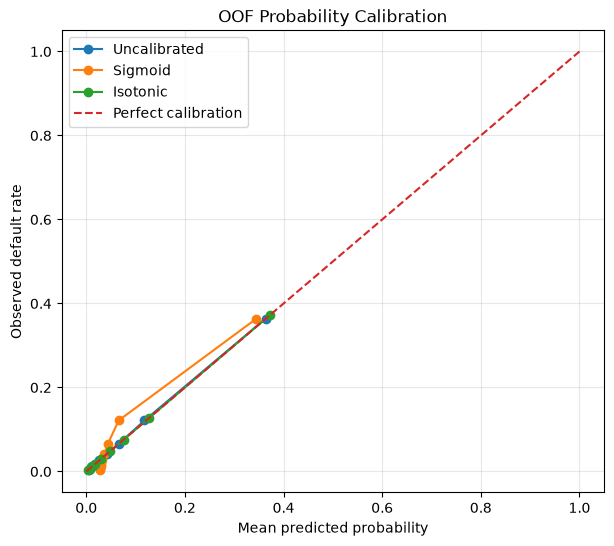

In [90]:
plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred_uncal,
    prob_true_uncal,
    marker="o",
    label="Uncalibrated"
)

plt.plot(
    prob_pred_sigmoid,
    prob_true_sigmoid,
    marker="o",
    label="Sigmoid"
)

plt.plot(
    prob_pred_isotonic,
    prob_true_isotonic,
    marker="o",
    label="Isotonic"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default rate")
plt.title("OOF Probability Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [91]:
calibration_results

,Model,Brier
0,Uncalibrated,0.049239
1,Sigmoid,0.050829
2,Isotonic,0.049106


In [92]:
discrimination_results

,Model,ROC-AUC,PR-AUC
0,Uncalibrated,0.864430,0.397184
1,Sigmoid,0.864430,0.397184
2,Isotonic,0.865156,0.390805


In [93]:
import numpy as np
import pandas as pd

thresholds = np.arange(0.05, 0.81, 0.01)

threshold_results = []

for threshold in thresholds:
    metrics = evaluate_predictions(
        oof_data["y_true"],
        oof_data["isotonic_probability"],
        threshold=threshold
    )
    
    threshold_results.append(metrics)

threshold_df = pd.DataFrame(threshold_results)

threshold_df.head()

,ROC-AUC,PR-AUC,KS,Brier,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Threshold
0,0.865156,0.390805,0.573842,0.049106,0.725723,0.176105,0.843660,0.291386,80319,31659,1254,6767,0.05
1,0.865156,0.390805,0.573842,0.049106,0.773423,0.200799,0.801895,0.321174,86378,25600,1589,6432,0.06
2,0.865156,0.390805,0.573842,0.049106,0.795523,0.214907,0.776088,0.336605,89237,22741,1796,6225,0.07
3,0.865156,0.390805,0.573842,0.049106,0.821632,0.235503,0.742800,0.357623,92637,19341,2063,5958,0.08
4,0.865156,0.390805,0.573842,0.049106,0.826465,0.239702,0.734946,0.361501,93280,18698,2126,5895,0.09


In [94]:
threshold_df[
    [
        "Threshold",
        "Precision",
        "Recall",
        "F1",
        "Accuracy",
        "FP",
        "FN",
        "TP",
        "TN"
    ]
].round(4)

,Threshold,Precision,Recall,F1,Accuracy,FP,FN,TP,TN
0,0.05,0.1761,0.8437,0.2914,0.7257,31659,1254,6767,80319
1,0.06,0.2008,0.8019,0.3212,0.7734,25600,1589,6432,86378
2,0.07,0.2149,0.7761,0.3366,0.7955,22741,1796,6225,89237
3,0.08,0.2355,0.7428,0.3576,0.8216,19341,2063,5958,92637
4,0.09,0.2397,0.7349,0.3615,0.8265,18698,2126,5895,93280
...,...,...,...,...,...,...,...,...,...
71,0.76,0.9412,0.0060,0.0119,0.9335,3,7973,48,111975
72,0.77,0.9412,0.0060,0.0119,0.9335,3,7973,48,111975
73,0.78,0.9412,0.0060,0.0119,0.9335,3,7973,48,111975
74,0.79,0.9412,0.0060,0.0119,0.9335,3,7973,48,111975


In [95]:
best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_f1_row

ROC-AUC           0.865156
PR-AUC            0.390805
KS                0.573842
Brier             0.049106
Accuracy          0.908716
Precision         0.372467
Recall            0.533973
F1                0.438832
TN           104762.000000
FP             7216.000000
FN             3738.000000
TP             4283.000000
Threshold         0.210000
Name: 16, dtype: float64

In [96]:
print("F1-optimal threshold:", best_f1_row["Threshold"])
print("Precision:", best_f1_row["Precision"])
print("Recall:", best_f1_row["Recall"])
print("F1:", best_f1_row["F1"])

F1-optimal threshold: 0.21000000000000002
Precision: 0.3724671710583529
Recall: 0.5339733200349084
F1: 0.43883196721311474


In [97]:
candidate_thresholds = [
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50
]

candidate_df = threshold_df[
    threshold_df["Threshold"].isin(candidate_thresholds)
][
    [
        "Threshold",
        "Precision",
        "Recall",
        "F1",
        "Accuracy",
        "FP",
        "FN",
        "TP",
        "TN"
    ]
].copy()

candidate_df.round(4)

,Threshold,Precision,Recall,F1,Accuracy,FP,FN,TP,TN
5,0.1,0.2591,0.7013,0.3784,0.8460,16085,2396,5625,95893
15,0.2,0.3716,0.5356,0.4388,0.9084,7265,3725,4296,104713


In [98]:
selected_reference_threshold = best_f1_row["Threshold"]

reference_metrics = evaluate_predictions(
    oof_data["y_true"],
    oof_data["isotonic_probability"],
    threshold=selected_reference_threshold
)

reference_metrics

{'ROC-AUC': 0.8651562891929929,
 'PR-AUC': 0.3908048381949536,
 'KS': np.float64(0.5738421691462277),
 'Brier': 0.04910640004043014,
 'Accuracy': 0.908715905965883,
 'Precision': 0.3724671710583529,
 'Recall': 0.5339733200349084,
 'F1': 0.43883196721311474,
 'TN': np.int64(104762),
 'FP': np.int64(7216),
 'FN': np.int64(3738),
 'TP': np.int64(4283),
 'Threshold': np.float64(0.21000000000000002)}

# 17. Final Test Evaluation

The predictive pipeline has now been completely frozen.

The frozen system consists of:

- Full feature set
- Frozen preprocessing
- Tuned XGBoost model
- No class weighting
- No monotonic constraints
- Frozen XGBoost hyperparameters
- Isotonic probability calibration
- Operating threshold = 0.21

The threshold of 0.21 was selected using the calibrated out-of-fold
development predictions by maximizing F1.

The test set has remained untouched throughout model development,
hyperparameter tuning, calibration, and threshold selection.

The test set will now be used exactly once for the final evaluation.

No changes will be made to:

- features
- preprocessing
- model
- hyperparameters
- calibration method
- threshold

after observing test performance.

In [99]:
from sklearn.base import clone
from xgboost import XGBClassifier

# Clone the frozen preprocessing configuration
final_preprocessor = clone(tree_preprocessor)

# Fit preprocessing ONLY on development data
X_dev_transformed = final_preprocessor.fit_transform(X_dev)

# Transform the locked test set
X_test_transformed = final_preprocessor.transform(X_test)

# Create the frozen XGBoost model
final_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    **FROZEN_XGB_PARAMS
)

# Train on ALL development data
final_model.fit(
    X_dev_transformed,
    y_dev
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.7
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [100]:
test_raw_probability = final_model.predict_proba(
    X_test_transformed
)[:, 1]

test_raw_probability[:10]

array([0.01109336, 0.0061613 , 0.01838538, 0.01916303, 0.02472595,
       0.06982216, 0.01051597, 0.2613365 , 0.00853036, 0.01049044],
      dtype=float32)

In [101]:
from sklearn.isotonic import IsotonicRegression

final_calibrator = IsotonicRegression(
    y_min=0,
    y_max=1,
    out_of_bounds="clip"
)

final_calibrator.fit(
    oof_data["oof_probability"],
    oof_data["y_true"]
)

,"y_min y_min: float, default=NoneLower bound on the lowest predicted value (the minimum value maystill be higher). If not set, defaults to -inf.",0
,"y_max y_max: float, default=NoneUpper bound on the highest predicted value (the maximum may still belower). If not set, defaults to +inf.",1
,"out_of_bounds out_of_bounds: {'nan', 'clip', 'raise'}, default='nan'Handles how `X` values outside of the training domain are handledduring prediction.- 'nan', predictions will be NaN.- 'clip', predictions will be set to the value corresponding to the nearest train interval endpoint.- 'raise', a `ValueError` is raised.",'clip'
,"increasing increasing: bool or 'auto', default=TrueDetermines whether the predictions should be constrained to increaseor decrease with `X`. 'auto' will decide based on the Spearmancorrelation estimate's sign.",True
Name,Type,Value
X_max_ X_max_: floatMaximum value of input array `X_` for right bound.,float64,0.8932
X_min_ X_min_: floatMinimum value of input array `X_` for left bound.,float64,0.002119
"X_thresholds_ X_thresholds_: ndarray of shape (n_thresholds,)Unique ascending `X` values used to interpolatethe y = f(X) monotonic function... versionadded:: 0.24","ndarray[float64](164,)","[0. ,0. ,0. ,...,0.86,0.86,0.89]"
f_ f_: functionThe stepwise interpolating function that covers the input domain ``X``.,interp1d,<scipy.interp...001C609CD9B30>
increasing_ increasing_: boolInferred value for ``increasing``.,bool,True
"y_thresholds_ y_thresholds_: ndarray of shape (n_thresholds,)De-duplicated `y` values suitable to interpolate the y = f(X)monotonic function... versionadded:: 0.24","ndarray[float64](164,)","[0. ,0. ,0. ,...,0.96,1. ,1. ]"


In [102]:
test_calibrated_probability = final_calibrator.predict(
    test_raw_probability
)

test_calibrated_probability[:10]

array([0.01170828, 0.00314356, 0.01562079, 0.02013575, 0.02459016,
       0.07222222, 0.01170828, 0.27619821, 0.00666878, 0.01170828])

In [103]:
FINAL_THRESHOLD = 0.21

In [104]:
test_predicted_class = (
    test_calibrated_probability >= FINAL_THRESHOLD
).astype(int)

In [105]:
final_test_metrics = evaluate_predictions(
    y_test,
    test_calibrated_probability,
    threshold=FINAL_THRESHOLD
)

final_test_metrics

{'ROC-AUC': 0.8696204835295223,
 'PR-AUC': 0.39185160603377994,
 'KS': np.float64(0.5882933316824032),
 'Brier': 0.04895814648068453,
 'Accuracy': 0.9103666666666667,
 'Precision': 0.3800841514726508,
 'Recall': 0.5406483790523691,
 'F1': 0.4463660695902821,
 'TN': np.int64(26227),
 'FP': np.int64(1768),
 'FN': np.int64(921),
 'TP': np.int64(1084),
 'Threshold': 0.21}

In [106]:
final_test_summary = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "KS",
        "Brier",
        "Precision",
        "Recall",
        "F1",
        "Accuracy",
        "TN",
        "FP",
        "FN",
        "TP",
        "Threshold"
    ],
    "Test": [
        final_test_metrics["ROC-AUC"],
        final_test_metrics["PR-AUC"],
        final_test_metrics["KS"],
        final_test_metrics["Brier"],
        final_test_metrics["Precision"],
        final_test_metrics["Recall"],
        final_test_metrics["F1"],
        final_test_metrics["Accuracy"],
        final_test_metrics["TN"],
        final_test_metrics["FP"],
        final_test_metrics["FN"],
        final_test_metrics["TP"],
        final_test_metrics["Threshold"]
    ]
})

final_test_summary

,Metric,Test
0,ROC-AUC,0.869620
1,PR-AUC,0.391852
2,KS,0.588293
3,Brier,0.048958
4,Precision,0.380084
5,Recall,0.540648
6,F1,0.446366
7,Accuracy,0.910367
8,TN,26227.000000
9,FP,1768.000000


In [107]:
oof_final_metrics = evaluate_predictions(
    oof_data["y_true"],
    oof_data["isotonic_probability"],
    threshold=FINAL_THRESHOLD
)

comparison_df = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "KS",
        "Brier",
        "Precision",
        "Recall",
        "F1",
        "Accuracy"
    ],
    "OOF Development": [
        oof_final_metrics["ROC-AUC"],
        oof_final_metrics["PR-AUC"],
        oof_final_metrics["KS"],
        oof_final_metrics["Brier"],
        oof_final_metrics["Precision"],
        oof_final_metrics["Recall"],
        oof_final_metrics["F1"],
        oof_final_metrics["Accuracy"]
    ],
    "Final Test": [
        final_test_metrics["ROC-AUC"],
        final_test_metrics["PR-AUC"],
        final_test_metrics["KS"],
        final_test_metrics["Brier"],
        final_test_metrics["Precision"],
        final_test_metrics["Recall"],
        final_test_metrics["F1"],
        final_test_metrics["Accuracy"]
    ]
})

comparison_df.round(4)

,Metric,OOF Development,Final Test
0,ROC-AUC,0.8652,0.8696
1,PR-AUC,0.3908,0.3919
2,KS,0.5738,0.5883
3,Brier,0.0491,0.0490
4,Precision,0.3725,0.3801
5,Recall,0.5340,0.5406
6,F1,0.4388,0.4464
7,Accuracy,0.9087,0.9104


## Final Test Evaluation — Interpretation

The final test evaluation measures the generalization performance of
the complete frozen credit-risk decision system.

The evaluation uses:

1. Frozen preprocessing
2. Frozen feature engineering
3. Frozen tuned XGBoost model
4. Frozen isotonic calibrator
5. Frozen operating threshold of 0.21

The threshold was selected exclusively using calibrated out-of-fold
development predictions and was not optimized using the test set.

The test set therefore provides an independent estimate of how the
final system performs on unseen borrowers.

The primary model-selection metric remains PR-AUC because the dataset
is highly imbalanced.

Secondary evaluation metrics include:

- ROC-AUC
- KS
- Brier score
- Precision
- Recall
- F1
- Accuracy

The confusion matrix is also reported to quantify false positives and
false negatives at the selected operating threshold.

No further model modifications will be made based on the final test
results. Any issue identified after this evaluation will be documented
as a potential future model iteration rather than used to modify Model 1.

In [108]:
final_model
final_preprocessor
final_calibrator
FINAL_THRESHOLD
final_test_metrics
comparison_df
FROZEN_XGB_PARAMS

{'subsample': 1.0,
 'reg_lambda': 2,
 'reg_alpha': 0.5,
 'n_estimators': 500,
 'min_child_weight': 10,
 'max_depth': 4,
 'learning_rate': 0.02,
 'gamma': 0,
 'colsample_bytree': 0.7}

In [110]:
FINAL_FEATURES = X_dev.columns.tolist()

print(f"Number of final features: {len(FINAL_FEATURES)}")
print(FINAL_FEATURES)

Number of final features: 20
['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'TotalDelinquency', 'HasDelinquency', 'HasSevereDelinquency', 'LogCreditUtilization', 'HighCreditUtilization', 'LogMonthlyIncome', 'IncomeCategory', 'LogDebtRatio', 'HighDebtRatio', 'TotalCreditAccounts']


In [112]:
MODEL_1_ARTIFACT_INFO = {
    "model_name": "Frozen XGBoost Model 1",
    "feature_set": "full",
    "features": FINAL_FEATURES,

    "class_weighting": False,
    "monotonic_constraints": False,

    "xgb_params": FROZEN_XGB_PARAMS,

    "calibration": "isotonic",
    "threshold": FINAL_THRESHOLD,
    "threshold_selection": "OOF F1 maximization",

    "primary_metric": "PR-AUC",

    "cv": {
        "type": "RepeatedStratifiedKFold",
        "n_splits": 5,
        "n_repeats": 2,
        "random_state": 42
    },

    "test_evaluation": final_test_metrics
}

MODEL_1_ARTIFACT_INFO

{'model_name': 'Frozen XGBoost Model 1',
 'feature_set': 'full',
 'features': ['RevolvingUtilizationOfUnsecuredLines',
  'age',
  'NumberOfTime30-59DaysPastDueNotWorse',
  'DebtRatio',
  'MonthlyIncome',
  'NumberOfOpenCreditLinesAndLoans',
  'NumberOfTimes90DaysLate',
  'NumberRealEstateLoansOrLines',
  'NumberOfTime60-89DaysPastDueNotWorse',
  'NumberOfDependents',
  'TotalDelinquency',
  'HasDelinquency',
  'HasSevereDelinquency',
  'LogCreditUtilization',
  'HighCreditUtilization',
  'LogMonthlyIncome',
  'IncomeCategory',
  'LogDebtRatio',
  'HighDebtRatio',
  'TotalCreditAccounts'],
 'class_weighting': False,
 'monotonic_constraints': False,
 'xgb_params': {'subsample': 1.0,
  'reg_lambda': 2,
  'reg_alpha': 0.5,
  'n_estimators': 500,
  'min_child_weight': 10,
  'max_depth': 4,
  'learning_rate': 0.02,
  'gamma': 0,
  'colsample_bytree': 0.7},
 'calibration': 'isotonic',
 'threshold': 0.21,
 'threshold_selection': 'OOF F1 maximization',
 'primary_metric': 'PR-AUC',
 'cv': {'type

In [113]:
import joblib

joblib.dump(final_model, "model_1_xgboost.joblib")
joblib.dump(final_preprocessor, "model_1_preprocessor.joblib")
joblib.dump(final_calibrator, "model_1_isotonic_calibrator.joblib")
joblib.dump(MODEL_1_ARTIFACT_INFO, "model_1_artifact_info.joblib")

['model_1_artifact_info.joblib']

In [5]:
import joblib

joblib.dump(X_dev, "X_dev.joblib")
joblib.dump(y_dev, "y_dev.joblib")

print("X_dev:", X_dev.shape)
print("y_dev:", y_dev.shape)

X_dev: (119999, 20)
y_dev: (119999,)
